### Sales Growth Drivers: 2024 vs. 2025

Let's look at how sales changed across product subcategories from 2024 to 2025.

We want to understand what might be behind the growth: are customers buying more products, are they buying different things, or are discounts playing a role?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
input_file = "../data/dear_neighbour.xlsx"

sheets = pd.read_excel(input_file, sheet_name=None)
sheet_names = sheets.keys()

sheet_names

dict_keys(['fact_sales', 'dim_products', 'dim_stores', 'dim_customers', 'dim_suppliers'])

In [17]:
sales = sheets['fact_sales']
products = sheets['dim_products']

[As we saw](https://github.com/TAbramovskaya/dear-neighbour/blob/main/python/data_overview.ipynb), selling prices remained relatively stable over the two-year period.

Therefore, we will overlook the fact that we have a single purchase price for each product across both years.

In [18]:
sales['year'] = sales['datetime'].dt.year

sales = (
    sales.merge(
        products[['product_id', 'category', 'subcategory', 'purchase_price_rub']],
        on='product_id',
        how='left'
    )
)

sales['unit_revenue'] = sales['line_total'] / sales['quantity']

sales['cost'] = sales['purchase_price_rub'] * sales['quantity']

sales['gross_profit'] = sales['line_total'] - sales['cost']

sales['gross_before_discount'] = sales['quantity'] * sales['unit_price']

sales['discount_amount'] = sales['gross_before_discount'] - sales['line_total']

sales['loyalty_receipts'] = sales.loc[sales['customer_id'].notna(), 'receipt_id']

In [19]:
summary_by_subcategory = (
    sales
    .groupby(['year', 'subcategory'])
    .agg(
        revenue=('line_total', 'sum'),
        gross_profit=('gross_profit', 'sum'),
        costs=('cost', 'sum'),
        quantity=('quantity', 'sum'),
        receipts=('receipt_id', 'nunique'),
        loyalty_receipts=('loyalty_receipts', 'nunique'),
        gross_before_discount=('gross_before_discount', 'sum'),
        discount_amount=('discount_amount', 'sum'),
        avg_discoutn_percent=('discount_percent', 'mean'),
    )
)

In [20]:
summary_by_subcategory['gross_margin'] = summary_by_subcategory['gross_profit'] / summary_by_subcategory['revenue']

summary_by_subcategory['revenue_share'] = (
    summary_by_subcategory['revenue']
    / summary_by_subcategory.groupby(level=['year'])['revenue'].transform('sum')
)

summary_by_subcategory['discount_share'] = (
    summary_by_subcategory['discount_amount']
    / summary_by_subcategory.groupby(level=['year'])['discount_amount'].transform('sum')
)

summary_by_subcategory['discount_share_of_profit'] = (
    summary_by_subcategory['discount_amount']
    / summary_by_subcategory['gross_profit'].replace(0, np.nan)
)

summary_by_subcategory['loyalty_receipts_share'] = (
    summary_by_subcategory['loyalty_receipts']
    / summary_by_subcategory.groupby(level=['year'])['loyalty_receipts'].transform('sum')
)

In [21]:
summary_by_subcategory[['revenue_share', 'discount_share', 'loyalty_receipts_share', 'discount_share_of_profit']]

revenue_share  discount_share  loyalty_receipts_share  \
year subcategory                                                          
2024 baked goods       0.008791        0.009726                0.033786   
     beef              0.032679        0.028138                0.008957   
     beer              0.013670        0.013764                0.030253   
     bread             0.009827        0.010981                0.032244   
     butter            0.005321        0.004789                0.005772   
...                         ...             ...                     ...   
2025 tea               0.015052        0.015064                0.013617   
     vegetables        0.018068        0.017657                0.037647   
     water             0.003854        0.003567                0.014640   
     wine              0.075252        0.072733                0.028435   
     yogurt            0.003294        0.003093                0.011970   

                  discount_share_of_profit  
year subcategory                            
2024 baked goods                  0.061552  
     beef                         0.099960  
     beer                         0.082390  
     bread                        0.092839  
     butter                       0.075974  
...                                    ...  
2025 tea                          0.061799  
     vegetables                   0.092740  
     water                        0.100502  
     wine                         0.065328  
     yogurt                       0.063468  

[98 rows x 4 columns]

In [23]:
wide = summary_by_subcategory.unstack('year')

metrics = {
    'gross_profit_change': ('gross_profit', 'pct'),
    'quantity_change': ('quantity', 'pct'),
    'revenue_share_change': ('revenue_share', 'pp'),
    'discount_share_change': ('discount_share', 'pp'),
    'discount_percent_of_profit_change': ('discount_share_of_profit', 'pp'),
    'loyalty_receipts_share_change': ('loyalty_receipts_share', 'pp'),
}

subcategories_yoy = pd.DataFrame(index=wide.index)

for column, (metric, change_type) in metrics.items():
    old = wide[metric][2024]
    new = wide[metric][2025]

    if change_type == 'pct':
        change = 100 * (new - old) / old.replace(0, np.nan)
    elif change_type == 'pp':
        change = 100 * (new - old)
    else:
        change = new - old

    subcategories_yoy[column] = change

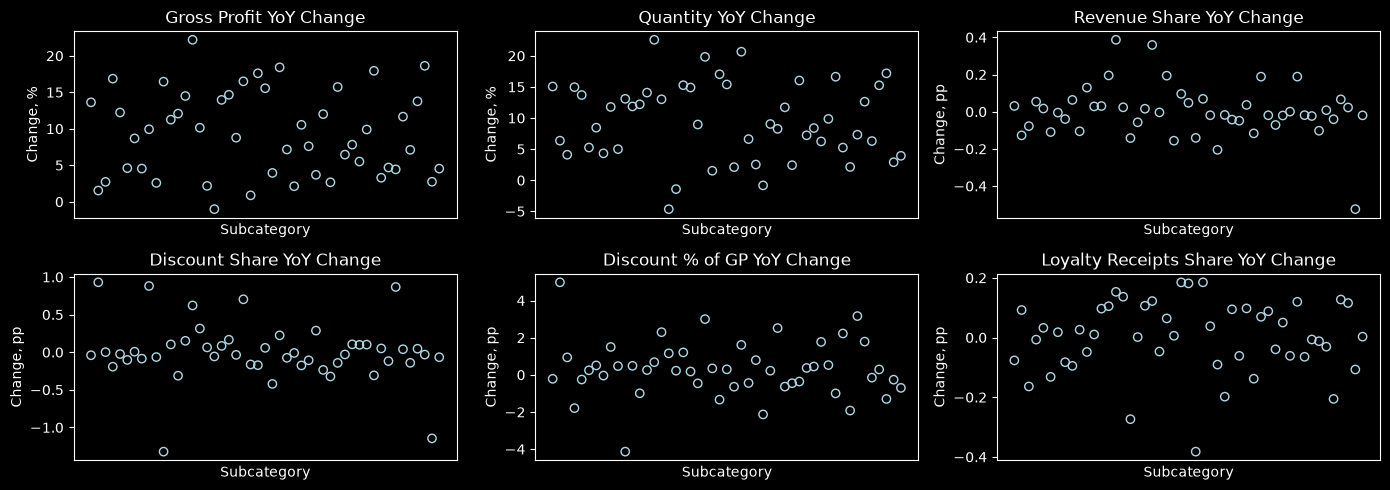

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(14, 5))

metrics = [
    ('gross_profit_change', 'Gross Profit YoY Change', 'Change, %'),
    ('quantity_change', 'Quantity YoY Change', 'Change, %'),
    ('revenue_share_change', 'Revenue Share YoY Change', 'Change, pp'),
    ('discount_share_change', 'Discount Share YoY Change', 'Change, pp'),
    ('discount_percent_of_profit_change', 'Discount % of GP YoY Change', 'Change, pp'),
    ('loyalty_receipts_share_change', 'Loyalty Receipts Share YoY Change', 'Change, pp'),
]

for ax, (column, title, ylabel) in zip(axes.flat, metrics):
    ax.scatter(
        subcategories_yoy.index,
        subcategories_yoy[column],
        facecolors='none',
        edgecolors='lightblue'
    )
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel('Subcategory')
    ax.set_xticks([])

plt.tight_layout()
plt.show()